##  Vincent Mui - October 2026

Required Assignment 17.1

# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



---

### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?


### Problem 1: Answer

The data is related with direct marketing campaigns of a Portuguese banking institution. The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be ('yes') or not ('no') subscribed

According to the **Materials and Methods** section of the paper *USING DATA MINING FOR BANK DIRECT MARKETING: AN APPLICATION OF THE CRISP-DM METHODOLOGY* [Moro et al., 2014], the bank direct marketing data represent **17 campaigns** that occurred between May 2008 and November 2010, corresponding to a total of 79,354 contacts. For each contact, a large number of attributes was stored and if there was a success (successful subscription to term deposit, the target variable y).  Data were collected from a Portuguese bank that used its own contact-center to do directed marketing campaigns by telephone.

The paper states there were 6,499 successes (8% success rate) with the original dataset. We will explore this rate again in the "Understanding the Features" section, because we are using different version of the bank dataset: 'bank-additional-full.csv' with all examples (41188) and 20 inputs, ordered by date (from May 2008 to November 2010), but still very close to the data analyzed in [Moro et al., 2014].

---

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings("ignore")

from scipy import stats

## scikit-learn imports, grouped by role
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)

from sklearn import set_config
# Setting this to display pipelines
set_config(display = "diagram") 

# Setting other display and plotting defaults
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [2]:
# Read bank information dataset
df = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [3]:
# Inspect first 5 rows
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Inspect last 5 rows
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,239,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


---

### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



### Steps to understand the data

Exploratory Data Analysis

- Examine data using summary statistics
- Detect skewness, and outliers
- Identify data quality issues: missing values, duplicate rows, incorrect data types, inconsistent strings, etc.
- Use visual charts to and correlation checks to understand variable relationships

In [5]:
# rows, columns, data types and non-null counts
print(df.shape)

# Explore metadata information
df.info()

(41188, 21)
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null

In [6]:
# Determine missing values and duplicate rows
print("Total missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Examine "pdays" data
print("Clients never previously contacted (pdays = 999):", f"{(df.pdays == 999).mean():.1%}")


Total missing values: 0
Duplicate rows: 12
Clients never previously contacted (pdays = 999): 96.3%


In [7]:
# Examine the "duplicated" rows reported above
df[df.duplicated()]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,43,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
20216,55,services,married,high.school,unknown,no,no,cellular,aug,mon,33,1,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228.1,no
20534,41,technician,married,professional.course,no,yes,no,cellular,aug,tue,127,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,no
25217,39,admin.,married,university.degree,no,no,no,cellular,nov,tue,123,2,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no


In [8]:
# Summary statistics for numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


In [9]:
# Descriptive statistics for categorical columns
df.describe(include=["str"]).T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


In [10]:
# "month" column has only 10 unique values instead of 12. Let's inspect the actual values:
print("'month' column - string values:", df["month"].unique())

'month' column - string values: <StringArray>
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'mar', 'apr', 'sep']
Length: 10, dtype: str


#### Initial Observation: Summary Statistics

96.3% of clients were never previously contacted (pdays = 999), therefore `pdays` column not useful for prediction.

Numeric columns have outliers that skews to the right:
- max `duration` value (4,918) is way higher than 75% of data (319)
- max `campaign` or number of contacts performed (56) is way higher than 75% of data (3)

Categorical columns:
- `month` column has only 10 unique values instead of 12. Upon inspection, "jan" and "feb" are not present in the data.
- a closer inspection on the actual unique values shows there are "unknown" values in some columns. Refer to EDA report below.

In [11]:
# Print EDA Report

print("="*100)
print("DATA UNDERSTANDING: EXPLORATORY DATA ANALYSIS REPORT")
print("="*100)

# 1. dataset dimensions
print("1. Total number of raw data rows and columns:", df.shape)
print("-"*100)

# 2. Investigate duplicates
print("2. Number of duplicate rows:", df.duplicated().sum())
print("   We will keep the duplicates because they represent real client records with different ages;\n   dropping them may distort the model.")
print("-"*100)

# 3. Detect outliers using Z-score
select_numeric_df = df[['age', 'duration', 'campaign']]
z_scores = np.abs(stats.zscore(select_numeric_df))
# Set threshold to 3 standard deviations (far from the Mean)
threshold = 3
outliers_df = select_numeric_df[z_scores > threshold]
print("3. Number of outliers:", outliers_df.shape[0])
print("-"*100)
# print("Outliers:", outliers_df)

# 4. Investigate useless column(s), after studying describe() statistics from above
print("4. Not useful data column - does not provide information to predict subscription targets")
# Examine "pdays" data; never previously contacted == 999
print("    'pdays' column data type:", df.pdays.dtype, ", proportion of clients never previously contacted:", f"{(df.pdays == 999).mean():.1%}")
print("-"*100)

# 5. Class balance of the target (Deposit Subscription)
print("5. Class balance of target variable (Deposit Subscription)")
counts = df["y"].value_counts()
rates = df["y"].value_counts(normalize=True)
print(pd.DataFrame({"count": counts, "proportion": rates.round(4)}))
print(f"   Overall successful subscription rate: {(df["y"] == 'yes').mean():.2%}")
print("-"*100)

# 6. Investigate missing values or bad data values
print("6. Missing values")
print("   Total Number of missing value in dataset:", df.isna().sum().sum())
print("   But number of missing values coded as 'unknown':")
print((df.select_dtypes("str") == "unknown").sum().loc[lambda s: s > 0])
print(f"   Proportion of unknown values in 'default' coloumn: {((df.default == "unknown").sum() / df.shape[0]):.2%}")
print("-"*100)


DATA UNDERSTANDING: EXPLORATORY DATA ANALYSIS REPORT
1. Total number of raw data rows and columns: (41188, 21)
----------------------------------------------------------------------------------------------------
2. Number of duplicate rows: 12
   We will keep the duplicates because they represent real client records with different ages;
   dropping them may distort the model.
----------------------------------------------------------------------------------------------------
3. Number of outliers: 2099
----------------------------------------------------------------------------------------------------
4. Not useful data column - does not provide information to predict subscription targets
    'pdays' column data type: int64 , proportion of clients never previously contacted: 96.3%
----------------------------------------------------------------------------------------------------
5. Class balance of target variable (Deposit Subscription)
     count  proportion
y                     
no

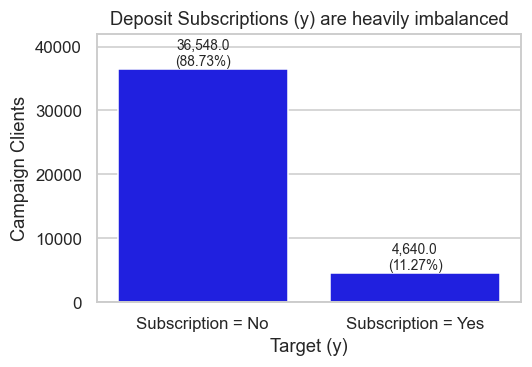

In [16]:
# Chart to visualize the target class imbalance
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x=df["y"].map({"no": "Subscription = No", "yes": "Subscription = Yes"}), color="blue", ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,}\n({p.get_height()/len(df):.2%})",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Deposit Subscriptions (y) are heavily imbalanced")
ax.set_xlabel("Target (y)")
ax.set_ylabel("Campaign Clients")
ax.set_ylim(0, 42000)
plt.tight_layout()
plt.savefig("images/target_count.png")
plt.show()

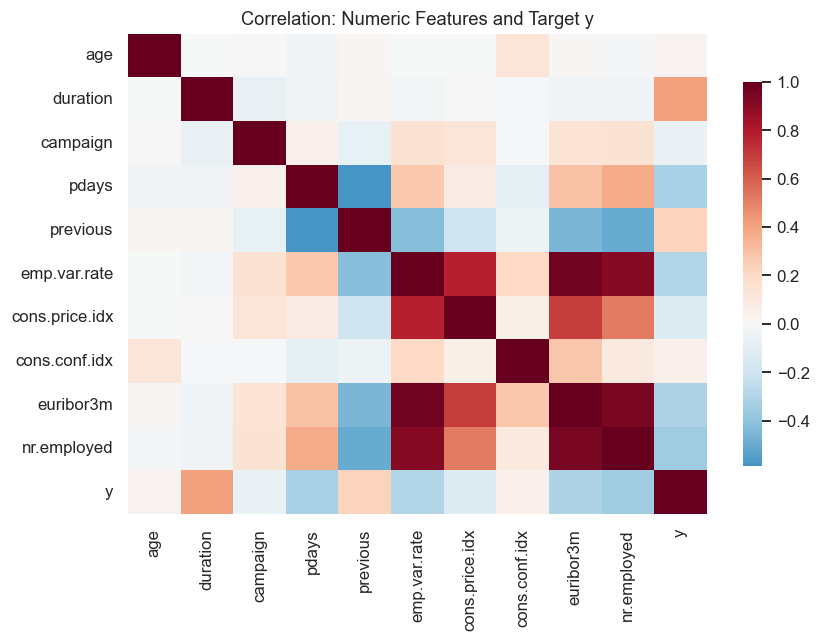

Correclation of numeric features and Target
duration          0.41
previous          0.23
cons.conf.idx     0.05
age               0.03
campaign         -0.07
cons.price.idx   -0.14
emp.var.rate     -0.30
euribor3m        -0.31
pdays            -0.32
nr.employed      -0.35
Name: y, dtype: float64


In [17]:
# Heatmap to visualize correlation among the numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_cols + ["y"]].assign(y = np.where(df["y"] == "yes", 1, 0)).corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=False, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation: Numeric Features and Target y")
plt.tight_layout()
plt.savefig("images/corr_heatmap.png")
plt.show()

# correlation of each numeric feature with the target, sorted
print("Correclation of numeric features and Target")
print(corr["y"].drop("y").sort_values(ascending=False).round(2))

Observations:
- `duration` (last contact call duration) has a noticeable positive relationship (0.41) with target variable "y". We need to examine whether it is related to No Subscriptions or Successful Subscriptions
    **Note:** the duration is not known before a call is performed, therefore duration = 0 will likely results in y = "no". We need to be careful when using duration as a predictor.
- `nr.employed` (number of bank employees) has an inverse relationship (-0.35) with target variable "y"
    i.e. More bank employees for the quarter, more No Subscriptions for term-deposits! 
    More employees just means more unsuccessful campaign calls were made.

#### Additional charts to dig deeper into possible replationships

In [18]:
# Seperate the 2 target classes for plotting different charts
df_no = df.loc[df["y"] == "no"]
df_yes = df.loc[df["y"] == "yes"]

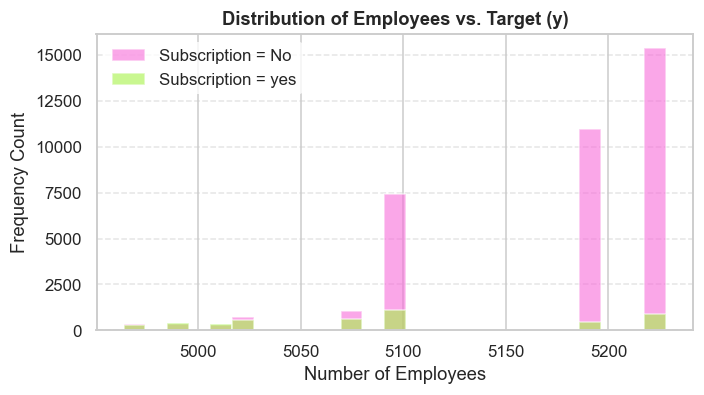

In [19]:
# Histograms to visualize relationship between number of bank employees and target

plt.figure(figsize=(7, 3.5))

# Plot overlapping histograms with alpha transparency
plt.hist(df_no['nr.employed'], bins=25, alpha=0.6, label='Subscription = No', color="#f76cd9", edgecolor='white')
plt.hist(df_yes['nr.employed'], bins=25, alpha=0.6, label='Subscription = yes', color="#a5f346", edgecolor='white')
plt.title('Distribution of Employees vs. Target (y)', fontweight='bold')
plt.xlabel('Number of Employees', fontsize=12)
plt.ylabel('Frequency Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='white', edgecolor='none')

plt.savefig("images/nr_employed_y_plot1.png")
plt.show()


Additonal Observation
- `nr.employed` (number of bank employees): The chart confirms `nr.employed` has an inverse relationship with target variable `y`. 
    i.e. More bank employees for the quarter resulted in just more calls with more No Subscriptions

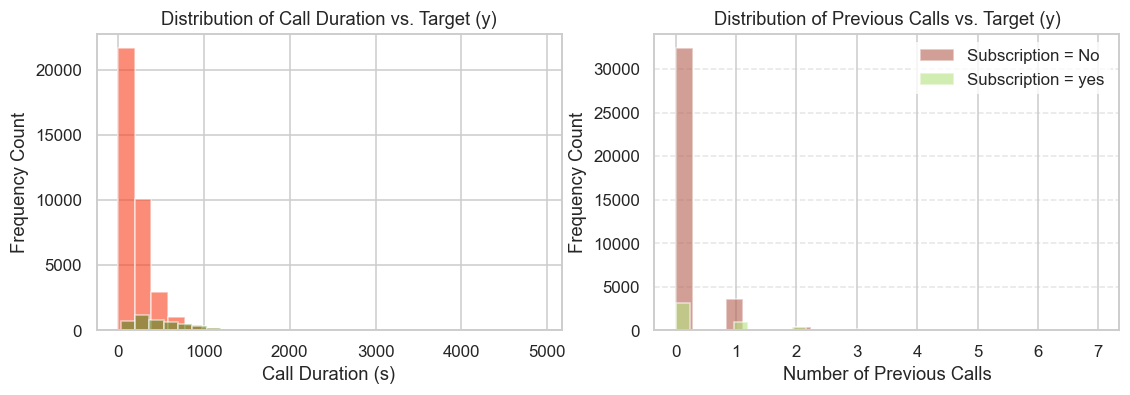

In [20]:
# Histograms to visualize relationship between call duration, previous calls, and target

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))

# Plot overlapping histograms with alpha transparency
ax[0].hist(df_no['duration'], bins=25, alpha=0.6, label='Subscription = No', color="#f93f1f", edgecolor='white')
ax[0].hist(df_yes['duration'], bins=25, alpha=0.6, label='Subscription = yes', color="#5c8a25", edgecolor='white')
ax[0].set(title="Distribution of Call Duration vs. Target (y)", xlabel="Call Duration (s)", ylabel="Frequency Count")
ax[1].hist(df_no['previous'], bins=25, alpha=0.6, label='Subscription = No', color="#b46051", edgecolor='white')
ax[1].hist(df_yes['previous'], bins=25, alpha=0.6, label='Subscription = yes', color="#b5e27f", edgecolor='white')
ax[1].set(title="Distribution of Previous Calls vs. Target (y)", xlabel="Number of Previous Calls", ylabel="Frequency Count")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='white', edgecolor='none')

plt.savefig("images/duration_previous_y_plot1.png")
plt.show()


Additonal Observation

- `duration` (last contact call duration) and `previous` (number of previous calls): have a mild inverse relationship with successful subscriptions. 
    i.e. Longer the last contact phone call or more previous calls resulted in slightly fewer successful subscriptions

In [22]:
# Manipulations of target, month, year columns for plotting purposes
plot_df = df.copy()

# Transform target column y to integers, mapping yes to 1 and no to 0
plot_df["subscribed"] = (plot_df.pop("y") == "yes").astype(int)
# Establish order and indexes for the 10 month values (not 12) in dataset
month_order = ["mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
month_idx = plot_df.month.map({m: i for i, m in enumerate(month_order)})
# Create and reconstruct year column
# Set base year = 2008
# Month index drops ==> new year has started. 
# Cumulative sum '1" ==> new year warp-around
year = 2008 + (month_idx.diff().fillna(0) < 0).cumsum()   
plot_df["year"] = year
# Show campaign calls by year, and deposit subscription success rates

print("-"*70)
print("Campaign Calls by Year and Deposit Subscription Success Rates")
print("-"*70)
print(plot_df.groupby("year").agg(campaign_calls=("subscribed","size"), success_rate=("subscribed","mean")).round(3))

----------------------------------------------------------------------
Campaign Calls by Year and Deposit Subscription Success Rates
----------------------------------------------------------------------
      campaign_calls  success_rate
year                              
2008           27690         0.048
2009           11440         0.195
2010            2058         0.521


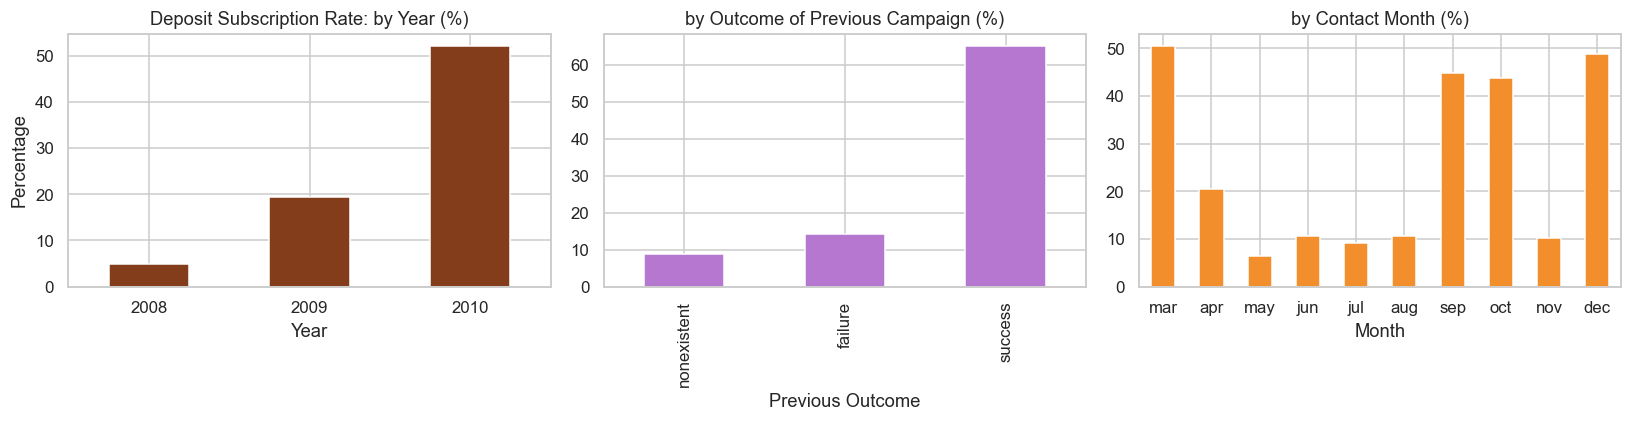

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
(plot_df.groupby("year").subscribed.mean() * 100).plot.bar(ax=ax[0], color="#833D1A", rot=0)
ax[0].set(title="Deposit Subscription Rate: by Year (%)", xlabel="Year", ylabel="Percentage")
poutcome_df = plot_df.groupby("poutcome").subscribed.mean().sort_values() * 100
poutcome_df.plot.bar(ax=ax[1], color="#b677d1")
ax[1].set(title="by Outcome of Previous Campaign (%)", xlabel="Previous Outcome")
month_df = (plot_df.groupby("month").subscribed.mean().reindex(month_order) * 100)
month_df.plot.bar(ax=ax[2], color="#f28e2b", rot=0)
ax[2].set(title="by Contact Month (%)", xlabel="Month")
plt.tight_layout()

plt.savefig("images/month_y_plot1.png")
plt.show()

Additonal charts: Observations
- `year`: Successful Subscription percentage rose over the years, although the number of calls fell
- `poutcome` (previous campaign outcome): is a strong predictor because previous campaign successes are closely related to current campaign successes.
- `month`: The following months show high successful subscription rates: Mar, Sep, Oct and Dec


---

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

#### Business Objective

**How should the bank prioritize campaign phone calls to sell term-deposits?**

Because positive responses to mass campaigns are typically very low, banks want to conduct ‘directed marketing campaigns’ that focus on targets who are keener to that specific product/service. In this exercise, we focus on using directed marketing campaigns to sell deposit applications with good interest rates. 

The business objective for the banks is to improve directed marketing campaigns efficiency to save costs and time – reduce phone contacts but improve the number of successes (clients subscribing the deposit). To achieve this objective, banks need to effectively prioritize their time and effort on contacts with the high responders to successfully sell deposit products.

Our task is to build a machine learning model to predict and classify the target population (e.g., high responders), based on the bank information features and probability of response/subscribing the deposit. Then banks can effectively prioritize directed marketing campaign efforts.

Also note that the overall successful deposit subscription rate is 11.27% from the dataset. A model that predicts "no deposit subscription" for every client is right 88.73% of the time is not very useful. Therefore that number is the accuracy our model should aim to beat.

#### Machine Learning Objective

Given the 20 original bank information features, predict the binary outcome `Term-Deposit Subscription`. 
We want to build and train a Machine Learning model to:

1. Beats the majority class baseline by a wide enough margin to justify deploying it,
2. Classifies the client population well, so that the bank's marketing team can prioritize and select clients for making telephone contacts
3. Is honest about the tradeoff between missing a successful client (who subscribes to term deposit) and wasting time to make telephone contacts.

#### Note: Accuracy may not be the appropriate evaluation metric

With an 88.73 percent majority class, accuracy rewards a model for predicting "no subscription". The bank may not care about the clients we correctly identify as non-subscribers. What matters is the minority class. We will still report accuracy, but will select models on F1 score, and we report ROC AUC as the ranking measure.




---

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.


### Bank Information Features Preparation: Data Cleaning and Transformation

Steps to construct final dataset prior to modeling:

Drop "duration" and "pdays" columns that are not useful for predictions:
- "duration" (as per Data Description above)
- "pdays" (as per EDA Report above)

Feature Engineering
- Drop missing values that were coded as "unknown"
- Some categorical columns are boolean; after taking out "unknown" values, convert remaining yes/no str values to 1/0 and pass them straight through:
  - "default"
  - "housing"
  - "loan"

Encoding
- Apply OneHotEncoder to categorical columns for regression models

Outliers
- Apply Interquartile range (IQR = 𝑄3 − 𝑄1 ) to detect outliers for elimination
- Apply to numeric columns "campaign"
- Note: "duration" column also has outliers but the whole column will be dropped as mentioned above

Scaling
- Data scaling will be performed, because both KNN and the RBF support vector machine depend on distances

Cross-validation 
- Train / Test Split: create a holdout "test set" for cross-validation to assess models' performance

In [24]:
# Make a copy of original data before data transformation and cleaning
df_cleaned = df.copy()

In [25]:
# Drop whole data column for "duration", "pdays"
df_cleaned.drop(columns = ["duration", "pdays"], inplace = True)

# Drop Values that are "unknown"
unknown_col_list = ["job", "marital", "education", "default", "housing", "loan"]
for column_name in unknown_col_list:
    df_cleaned = df_cleaned[df_cleaned[column_name] != "unknown"]

# After taking out "unknown" values, convert remaining yes/no values to 1/0 and pass it straight through later
boo_col_list = ["default", "housing", "loan"]
for column_name in boo_col_list:
    df_cleaned[column_name] = df_cleaned[column_name].map({'yes': 1, 'no': 0})

In [26]:
# Clean up outliers in column "campaign", using Interquartile range (IQR = 𝑄3 − 𝑄1 )
# Note: "duration" column also has outliers but the whole column will be dropped as mentioned above
# Note: "age" column also has outliers, but the age of 95 seems legitimate, therefore no cleaning applied
q_1 = df_cleaned["campaign"].quantile(.25)
q_3 = df_cleaned["campaign"].quantile(.75)
iqr = q_3 - q_1
lower = q_1 - (1.5 * iqr)
upper = q_3 + (1.5 * iqr)
df_cleaned = df_cleaned.loc[(df_cleaned[ "campaign"] > lower) & (df_cleaned[ "campaign"] < upper)]

# Check statistics again
df_cleaned.describe()

,age,default,housing,loan,campaign,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,28117.000000,28117.000000,28117.000000,28117.000000,28117.000000,28117.000000,28117.000000,28117.000000,28117.000000,28117.000000,28117.000000
mean,39.039158,0.000107,0.542874,0.155600,1.928904,0.203613,-0.126486,93.508668,-40.586866,3.406346,5158.338589
std,10.376306,0.010329,0.498167,0.362482,1.118287,0.534195,1.618507,0.587682,4.853259,1.786552,75.811987
min,17.000000,0.000000,0.000000,0.000000,1.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,31.000000,0.000000,0.000000,0.000000,1.000000,0.000000,-1.800000,92.963000,-42.700000,1.313000,5099.100000
50%,37.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.100000,93.444000,-41.800000,4.855000,5191.000000
75%,45.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,95.000000,1.000000,1.000000,1.000000,5.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [27]:
# Print Post-Cleaning audit report
print("="*100)
print("DATA PREPARATION: DATA CLEANING AND TRANSFORMATION AUDIT")
print("="*100)
print("Total number of original data rows and columns:", df.shape)
print("Total number after cleaning - rows and columns:", df_cleaned.shape)
print("Re-check: number of missing values =", df.isnull().sum().sum())
print(df_cleaned.info())
print("="*100)

DATA PREPARATION: DATA CLEANING AND TRANSFORMATION AUDIT
Total number of original data rows and columns: (41188, 21)
Total number after cleaning - rows and columns: (28117, 19)
Re-check: number of missing values = 0
<class 'pandas.DataFrame'>
Index: 28117 entries, 0 to 41187
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             28117 non-null  int64  
 1   job             28117 non-null  str    
 2   marital         28117 non-null  str    
 3   education       28117 non-null  str    
 4   default         28117 non-null  int64  
 5   housing         28117 non-null  int64  
 6   loan            28117 non-null  int64  
 7   contact         28117 non-null  str    
 8   month           28117 non-null  str    
 9   day_of_week     28117 non-null  str    
 10  campaign        28117 non-null  int64  
 11  previous        28117 non-null  int64  
 12  poutcome        28117 non-null  str    
 13  emp.var.rat

In [28]:
# Transform target column y to integers, mapping yes to 1 and no to 0
y = np.where(df_cleaned["y"] == "yes", 1, 0)

# Separate the target variable from the bank info features
X = df_cleaned.drop("y", axis = 1)

In [29]:
# Declare different column sets for different treatments later

numeric_features = ["age", "campaign", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

categorical_features = ["job", "marital", "education", "contact", "month", "day_of_week", "poutcome", ]

# These are engineered features (yes/no already converted to 1/0)
passthrough_features = ["default", "housing", "loan"]


In [30]:
# Print info
print("="*100)
print("DATA PREPARATION: PREDICTOR MATRIX AND TARGET")
print("="*100)
print("Predictor matrix    :", X.shape)
print("Nnumeric features   :", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Passthrough features:", len(passthrough_features))
print("-"*100)
print(f"Target positive rate (successful subscription): {y.mean():.2%}")
print("="*100)

DATA PREPARATION: PREDICTOR MATRIX AND TARGET
Predictor matrix    : (28117, 18)
Nnumeric features   : 8
Categorical features: 7
Passthrough features: 3
----------------------------------------------------------------------------------------------------
Target positive rate (successful subscription): 13.22%


In [33]:
# Build a preprocessor as a reusable function, so we can vary the numeric list later
def make_preprocessor(numeric_cols = numeric_features):
    return ColumnTransformer(
        transformers = [
            ("num", StandardScaler(), numeric_cols),
            ("cat", OneHotEncoder(drop = "first", handle_unknown = "ignore"), categorical_features),
            ("pass", "passthrough", passthrough_features),
        ]
    )

preprocessor = make_preprocessor()
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

---

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

We will use `test_size=0.33`, `random_state=10`, and a stratified split, so that both halves carry the same positive rate. With a 13.22 percent minority class, a random/unstratifiedsplit can produce noticeably different base rates in the two halves by chance.

In [34]:
# Stratified Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=10, stratify=y)

In [35]:
# Print post-split info
print("="*100)
print("DATA PREPROCESSING: TRAIN/TEST SPLIT")
print("="*100)
print(f"Train set: {X_train.shape}, Train set positive rate: {y_train.mean():.2%}")
print(f"Test set : {X_test.shape}, Test set positive rate: {y_test.mean():.2%}")

# Check if any of categorical feature columns that appear in only one half of the split:
imbalance_in_split = False
for col in categorical_features:
    train_only = sorted(set(X_train[col]) - set(X_test[col]))
    test_only = sorted(set(X_test[col]) - set(X_train[col]))
    if train_only or test_only:
        print(f"{col:20s} in train set only: {train_only}  in test set only: {test_only}")
        imbalance_in_split = True
if imbalance_in_split == False:
    print("There is no imbalance of categorical features caused by the split.")

# Check matrix size after data transformation (one-hot encoding)
n_features_out = make_preprocessor().fit_transform(X_train).shape[1]
print("-"*100)
print("Number of feature columns before data preprocessing:", X_train.shape[1])
print("Number of feature columns after data preprocessing :", n_features_out)
print("="*100)

DATA PREPROCESSING: TRAIN/TEST SPLIT
Train set: (18838, 18), Train set positive rate: 13.22%
Test set : (9279, 18), Test set positive rate: 13.22%
There is no imbalance of categorical features caused by the split.
----------------------------------------------------------------------------------------------------
Number of feature columns before data preprocessing: 18
Number of feature columns after data preprocessing : 45


Observation:

We have expanded 18 fearure columns to 45, after encoding. We will explore if such an expansion will create distance issues in running a KNN model later.

---

### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [36]:
# Establish the majority class baseline
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

baseline_train_acc = dummy.score(X_train, y_train)
baseline_test_acc = dummy.score(X_test, y_test)

# Generate other scoring metrics
# Note: Since our baseline gets zero of the positives, so its recall and F1 on the positive class are zero
baseline_pred = dummy.predict(X_test)

print("="*100)
print("BASELINE MODEL")
print("="*100)
print(f"Baseline Train set accuracy: {baseline_train_acc:.2%}")
print(f"Baseline Test set accuracy: {baseline_test_acc:.2%}")
print("-"*100)
print("Baseline precision:", round(precision_score(y_test, baseline_pred, zero_division=0), 4))
print("Baseline recall:   ", round(recall_score(y_test, baseline_pred), 4))
print("Baseline F1:       ", round(f1_score(y_test, baseline_pred), 4))
print("="*100)

BASELINE MODEL
Baseline Train set accuracy: 86.78%
Baseline Test set accuracy: 86.78%
----------------------------------------------------------------------------------------------------
Baseline precision: 0.0
Baseline recall:    0.0
Baseline F1:        0.0


Observation:

Our baseline model achieves 86.78% percent accuracy predicting "no" but reaches *no* "successful term-deposit subscriber". Therefore using accuracy score alone may not be sufficient on model evaluation.  

---

### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [37]:
# Build a basic model using Logistic Regression with default settings and a pipeline
logreg_pipe = Pipeline([
    ("transformer", make_preprocessor()),
    ("model", LogisticRegression(max_iter=1000)),
])

# Fit the basic model with training set
logreg_pipe.fit(X_train, y_train)
print("Model Fitted:", logreg_pipe.named_steps["model"])


Model Fitted: LogisticRegression(max_iter=1000)


---

### Problem 9: Score the Model

What is the accuracy of your model?

In [38]:
# Accuracy Scores for the training and test sets, for our simple Logistic Regression model
logreg_train_acc = logreg_pipe.score(X_train, y_train)
logreg_test_acc = logreg_pipe.score(X_test, y_test)

# Get the full picture on the test set with a classification report
logreg_pred = logreg_pipe.predict(X_test)
logreg_proba = logreg_pipe.predict_proba(X_test)[:, 1]
logreg_report_dict = classification_report(y_test, logreg_pred, target_names=["No Subscription", "Subscription"], output_dict=True)
logreg_roc_auc = roc_auc_score(y_test, logreg_proba)

print("="*100)
print("Accuracy Scores for the simple Logistic Regression model")
print("-"*100)
print(f"Train set accuracy score: {logreg_train_acc:.2%}")
print(f"Test set accuracy score: {logreg_test_acc:.2%}")
print("Improvement over baseline model's score:", round(logreg_test_acc - baseline_test_acc, 4))
print("="*100)
print("Other Metrics for the simple Logistic Regression model")
print("-"*100)
print(pd.DataFrame(logreg_report_dict).round(4))
print("-"*100)
print("ROC AUC:", round(logreg_roc_auc, 4))
print("="*100)


Accuracy Scores for the simple Logistic Regression model
----------------------------------------------------------------------------------------------------
Train set accuracy score: 88.42%
Test set accuracy score: 88.39%
Improvement over baseline model's score: 0.0162
Other Metrics for the simple Logistic Regression model
----------------------------------------------------------------------------------------------------
           No Subscription  Subscription  accuracy  macro avg  weighted avg
precision           0.8955        0.6630    0.8839     0.7792        0.8647
recall              0.9808        0.2486    0.8839     0.6147        0.8839
f1-score            0.9362        0.3616    0.8839     0.6489        0.8602
support          8052.0000     1227.0000    0.8839  9279.0000     9279.0000
----------------------------------------------------------------------------------------------------
ROC AUC: 0.793


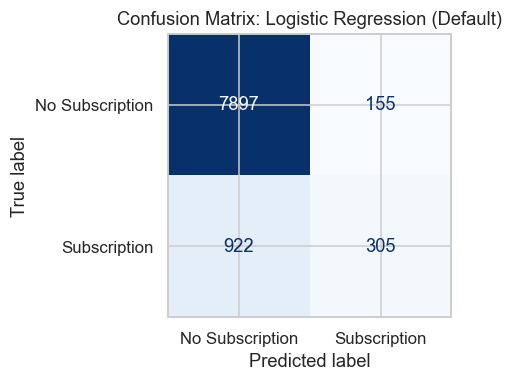

In [39]:
# Evaluate our simple Logistic Regression model using Confusion Matrix
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, logreg_pred, display_labels=["No Subscription", "Subscription"],
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Confusion Matrix: Logistic Regression (Default)")
plt.tight_layout()

plt.savefig("images/c_matrix_logreg.png")
plt.show()

Obesrvations

The confusion matrix and other evaluation metrics confirms our previous observation that:
- The target classes (Yes/No on term-deposit subscriptions) are highly imbalanced
- Therefore Accuracy Score is not a good evaluation metric in this case
 
Possible better choices for model evaluation metrics
- F1-Score for the positive class, as a weighted average of both Precision and Recall
- ROC AUC, as ranking quality


---

### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [40]:
# Define the 4 basic models with default settings
basic_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=10),
    "SVM (Gaussian kernel)": SVC(random_state=10)     # Use "probability=True" instead of distance default if  ROC-AUC curves needed
}
list(basic_models)

['Logistic Regression',
 'K-Nearest Neighbors',
 'Decision Tree',
 'SVM (Gaussian kernel)']

In [41]:
# Initialize classifier comparison results list
comparison_results = []

# Add Baseline numbers to comparison results table
comparison_results.append({
    "Model": "Baseline (Majority Class)",
    "Train Time(s)": 0.000,
    "Train Accuracy": baseline_train_acc,
    "Test Accuracy": baseline_test_acc,
    "F1-Score (Pos Class)": "N/A",
    "ROC AUC": "N/A"
})

# Use a pipeline to fit one model at a time, and record the train time, train accuracy, and test accuracy
for name, classifier in basic_models.items():
    pipe = Pipeline([("transformer", make_preprocessor()), 
                     ("model", classifier)]
                     )
    # Capture time before and after fitting a model
    start_time = time.time()
    pipe.fit(X_train, y_train)
    elapsed_time = time.time() - start_time
    # Make model predictions using train set and test set
    pred_train = pipe.predict(X_train)
    pred_test = pipe.predict(X_test)
    # Use decision_function instead of predict_proba for SVM (SVC without probability=True)
    if hasattr(pipe, "predict_proba"):
        score_test = pipe.predict_proba(X_test)[:, 1]
    else:
        score_test = pipe.decision_function(X_test)
    report_dict = classification_report(y_test, pred_test, target_names=["No Subscription", "Subscription"], output_dict=True)
    # Save train time and evaluation metrics for each basic model
    comparison_results.append({
        "Model": name,
        "Train Time(s)": round(elapsed_time, 3),
        "Train Accuracy": accuracy_score(y_train, pred_train),
        "Test Accuracy": accuracy_score(y_test, pred_test),
        "F1-Score (Pos Class)": report_dict['Subscription']['f1-score'],
        "ROC AUC": round(roc_auc_score(y_test, score_test), 4)
    })

# Convert basic model comparison metrics to dataframe for later use
basic_results_df = pd.DataFrame(comparison_results).round(4)

# Metrics Report
print("="*120)
print("Classification Metrics Report - 4 Basic Models")
print("="*120)
print(basic_results_df)
print("="*120)


Classification Metrics Report - 4 Basic Models
                       Model  Train Time(s)  Train Accuracy  Test Accuracy F1-Score (Pos Class) ROC AUC
0  Baseline (Majority Class)          0.000          0.8678         0.8678                  N/A     N/A
1        Logistic Regression          0.103          0.8842         0.8839             0.361589   0.793
2        K-Nearest Neighbors          0.031          0.9003         0.8707             0.378882  0.7294
3              Decision Tree          0.128          0.9945         0.8220             0.350118  0.6303
4      SVM (Gaussian kernel)          6.135          0.8905         0.8855             0.350856  0.7256


#### Observations

**Test Accuracy**
- For our 4 basic models, SVM with a Gaussian kernel performs best in terms of Test Accuracy. 
- As mentioned, Accuracy Score may not be the best classifier evaluation metric due to imbalance in class. Also, Test Accuracy varies very less across the 4 basic models. 

**F1-Score**
- KNN has the second lowest Test Accuracy of the four, but the highest F1-Score for positive class. 
- This demonstrates ranking these models based on accuracy alone is not sufficient. 

**ROC AUC**
- The unconstrained Decision Tree has the lowest ROC AUC score of 0.6303, because a fully grown tree drives its leaf probabilities to zero or one, and leaves the ranking
almost nothing to work with. We shall see if tuning will help on the Decision Tree. 
- K-nearest neighbors ROC AUC score of 0.7294 is not high, likely due to the use of encoder that expand the dimensionality from 18 feature columns to 45 columns

#### Revisit Bank Information Feature Set

In [43]:
# With our cleaned data, explore permutation importance using a small Decision Tree model (depth = 3), to see which features are better predictors
probe_tree = Pipeline([
    ("transformer", make_preprocessor()),
    ("model", DecisionTreeClassifier(random_state=10, max_depth=3, criterion="entropy")),
    ]).fit(X_train, y_train)

perm = permutation_importance(probe_tree, X_test, y_test, scoring="f1", n_repeats=10, random_state=10)

importance = (pd.Series(perm.importances_mean, index=X_test.columns)
                .sort_values(ascending=False))

print(importance.head(8).round(4).to_string())


poutcome       0.2473
nr.employed    0.2312
month          0.0302
euribor3m      0.0067
job            0.0000
age            0.0000
housing        0.0000
marital        0.0000


Observation

According to our small Decision Tree model, "poutcome" (previous campaign outcome) and "nr.employed" (number of bank employees) are top predictors. As seen on the correlation chart before, nr.employed has an inverse relationship with target "subscribed".

---

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

#### Hyperparameter Tuning and Grid Search with Cross-validation

Considerations
- We will create a grid for each model with various hyperparameters for tuning performances
- To address the class imbalance observed in previous sections, we will include `class_weight="balanced"` (for the models that support it). That option reweights the loss so
that the minority class (successful term-deposit subscription) counts more.
- For performance evaluation, we will use **F1 for the positive class** and **ROC  AUC**, as explained in previous sections
- We will use a five-fold stratified cross-validation on training set

In [44]:
# Create a single cross-validation object for grid search use
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)

# Establish parameter grids for each model
param_grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, solver="liblinear"),
        {"model__C": [0.01, 0.1, 1, 10],
         "model__penalty": ["l1", "l2"],
         "model__class_weight": [None, "balanced"]},
    ),
    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [5, 11, 21, 31, 51],
         "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=10),
        {"model__max_depth": [3, 5, 7, 10, None],
         "model__min_samples_leaf": [1, 5, 20, 50],
         "model__criterion": ["gini", "entropy"],
         "model__class_weight": [None, "balanced"]},
    ),
    "SVM (Gaussian kernel)": (
        SVC(random_state=10),
        {"model__C": [0.1, 1, 10],
         "model__gamma": ["scale", 0.01, 0.1],
         "model__class_weight": [None, "balanced"]},
    ),
}

# A quick check on the number of fits for each grid search
print("Intended number of fits for grid search")
for name, (_, grid) in param_grids.items():
    n_combos = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name:22s} {n_combos:3d} combinations x 5 folds = {n_combos * 5:4d} fits")

Intended number of fits for grid search
Logistic Regression     16 combinations x 5 folds =   80 fits
K-Nearest Neighbors     20 combinations x 5 folds =  100 fits
Decision Tree           80 combinations x 5 folds =  400 fits
SVM (Gaussian kernel)   18 combinations x 5 folds =   90 fits


In [45]:
# Execute grid search for best hyper-parameters for each model type
searches = {}         # GridSearch best model dict
tuning_results = []   # Performance Metrics

for name, (classifier, grid) in param_grids.items():
    print(f"GridSearch Started: {name}")
    pipe = Pipeline([("transformer", make_preprocessor()), 
                    ("model", classifier)]
                    )
    # Capture time before and after grid search, and fitting the best model
    start_time = time.time()
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    elapsed_time = time.time() - start_time
    searches[name] = search
    # Make model predictions using test set
    pred_test = search.predict(X_test)
    # Use decision_function instead of predict_proba for SVM (SVC without probability=True)
    if hasattr(search.best_estimator_, "predict_proba"):
        score = search.predict_proba(X_test)[:, 1]
    else:
        score = search.decision_function(X_test)
    report_dict = classification_report(y_test, pred_test, target_names=["No Subscription", "Subscription"], output_dict=True)
    # Save performance metrics for best model for each Classifier Type
    tuning_results.append({
        "Model": name,
        "Search Time(s)": round(elapsed_time, 1),
        "CV F1": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, pred_test),
        "Test Precision": precision_score(y_test, pred_test, zero_division=0),
        "Test Recall": recall_score(y_test, pred_test),
        # Save F1 Score for positive class
        "Test F1": report_dict['Subscription']['f1-score'],  
    #   "Test F1": f1_score(y_test, pred_test),
        "Test ROC AUC": roc_auc_score(y_test, score),
    })
    print(f"GridSearch Completed: {name}")

# Convert tuned model metrics to dataframe for later use
tuned_results_df = pd.DataFrame(tuning_results).round(4)

# Performance Metrics for best model for each Classifier Type
print("="*120)
print("Hyperparameter Tuning Report - Metrics for each 'Best' Model")
print("="*120)
print(tuned_results_df)
print("="*120)


GridSearch Started: Logistic Regression
GridSearch Completed: Logistic Regression
GridSearch Started: K-Nearest Neighbors
GridSearch Completed: K-Nearest Neighbors
GridSearch Started: Decision Tree
GridSearch Completed: Decision Tree
GridSearch Started: SVM (Gaussian kernel)
GridSearch Completed: SVM (Gaussian kernel)
Hyperparameter Tuning Report - Metrics for each 'Best' Model
                   Model  Search Time(s)   CV F1  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC AUC
0    Logistic Regression            11.0  0.4773         0.8029          0.3657       0.6683   0.4728        0.7928
1    K-Nearest Neighbors            12.3  0.3755         0.8622          0.4686       0.3162   0.3776        0.7252
2          Decision Tree             6.6  0.5004         0.8439          0.4340       0.5925   0.5010        0.7763
3  SVM (Gaussian kernel)           278.1  0.4924         0.8235          0.3974       0.6487   0.4929        0.7799


#### Tuning Results: High-level Obervation

A tuned Decision Tree model resulted in the best Test Set F1-Score, and okay Test Accuracy Score.

Note: F1-Score for Positive Target Class is used

In the next sections, we will examine the gains in Accuracy Score, F1-Score, and ROC from our tuning exercise, and adjust our primary performance metric accordingly.

In [46]:
# Report on the best hyperparameters for each model type from GridSearch
print("="*120)
print("Hyperparameter Tuning Report - Best Parameters for each Classifier Type")
print("="*120)
for name, search in searches.items():
    cleaned_text = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:22s} {cleaned_text}")
print("="*120)

Hyperparameter Tuning Report - Best Parameters for each Classifier Type
Logistic Regression    {'C': 1, 'class_weight': 'balanced', 'penalty': 'l2'}
K-Nearest Neighbors    {'n_neighbors': 5, 'p': 1, 'weights': 'distance'}
Decision Tree          {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 5}
SVM (Gaussian kernel)  {'C': 1, 'class_weight': 'balanced', 'gamma': 0.1}


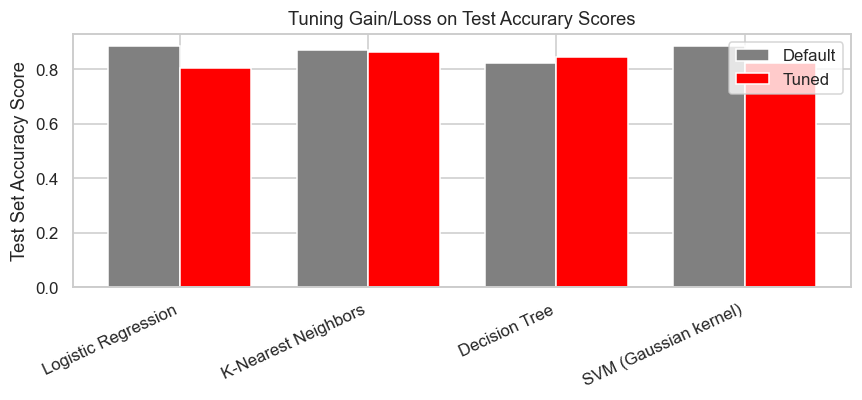

,Model,Default Accuracy,Tuned Accuracy,Gain
0,Logistic Regression,0.8839,0.8029,-0.0810
1,K-Nearest Neighbors,0.8707,0.8622,-0.0085
2,Decision Tree,0.8220,0.8439,0.0219
3,SVM (Gaussian kernel),0.8855,0.8235,-0.0620


In [48]:
# Bar chart to compare Accuracy Score of default settings models vs tuned models

# Merge basic model metrics with tuned model metrics
accuracy_df = (basic_results_df[["Model", "Test Accuracy"]].rename(columns={"Test Accuracy": "Default Accuracy"})
        .merge(tuned_results_df[["Model", "Test Accuracy"]].rename(columns={"Test Accuracy": "Tuned Accuracy"}), 
        on="Model")
        )
# Calculate gain on F1 Scores
accuracy_df["Gain"] = (accuracy_df["Tuned Accuracy"] - accuracy_df["Default Accuracy"]).round(4)

# Bar chart
idx = np.arange(len(accuracy_df))
width = 0.38
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(idx - width / 2, accuracy_df["Default Accuracy"], width, label="Default", color="grey")
ax.bar(idx + width / 2, accuracy_df["Tuned Accuracy"], width, label="Tuned", color="red")
ax.set_xticks(idx)
ax.set_xticklabels(accuracy_df["Model"], rotation=25, ha="right")
ax.set_ylabel("Test Set Accuracy Score")
ax.set_title("Tuning Gain/Loss on Test Accurary Scores")
ax.legend()
plt.tight_layout()

plt.savefig("images/tuned_accuracy_plot.png")
plt.show()

accuracy_df

#### Obesrvations - Tuning and Accuracy Score

Our hyperparameter tuning exercise did not improve Accuracy Scores much; in fact it degraded 3 out of the 4 default models!

#### Adjustment to Performance Metric

Because our tuning did not affect Accuracy Scores much, Accuracy Score may not be a deciding metric. Just like we mentioned before, Accuracy Score is not a good metric for this exercise with huge target class imbalance. Therefore we will turn to F1-Score next.

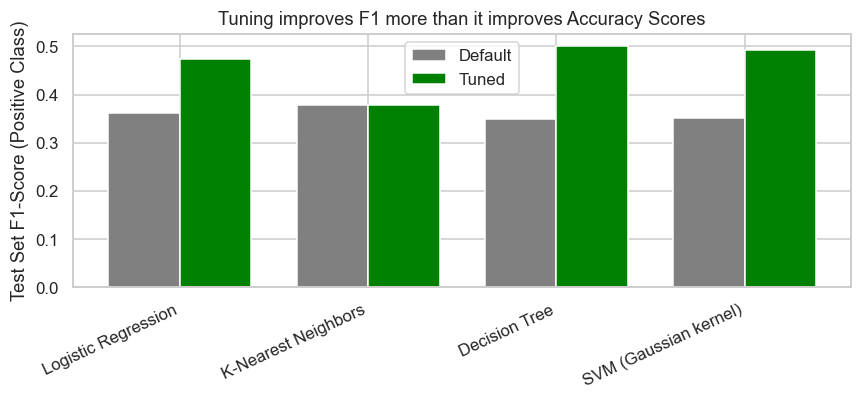

,Model,Default F1,Tuned F1,Gain
0,Logistic Regression,0.361589,0.4728,0.1112
1,K-Nearest Neighbors,0.378882,0.3776,-0.0013
2,Decision Tree,0.350118,0.5010,0.1509
3,SVM (Gaussian kernel),0.350856,0.4929,0.142


In [50]:
# Bar chart to compare F1-score (Positive Class) of default settings models vs tuned models

# Merge basic model metrics with tuned model metrics
f1_df = (basic_results_df[["Model", "F1-Score (Pos Class)"]].rename(columns={"F1-Score (Pos Class)": "Default F1"})
        .merge(tuned_results_df[["Model", "Test F1"]].rename(columns={"Test F1": "Tuned F1"}), 
        on="Model")
        )
# Calculate gain on F1 Scores
f1_df["Gain"] = (f1_df["Tuned F1"] - f1_df["Default F1"]).round(4)

# Bar chart
idx = np.arange(len(f1_df))
width = 0.38
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(idx - width / 2, f1_df["Default F1"], width, label="Default", color="grey")
ax.bar(idx + width / 2, f1_df["Tuned F1"], width, label="Tuned", color="green")
ax.set_xticks(idx)
ax.set_xticklabels(f1_df["Model"], rotation=25, ha="right")
ax.set_ylabel("Test Set F1-Score (Positive Class)")
ax.set_title("Tuning improves F1 more than it improves Accuracy Scores")
ax.legend()
plt.tight_layout()

plt.savefig("images/tuned_f1_plot.png")
plt.show()

f1_df

#### Obesrvations - Tuning and F1-Score

- Our hyperparameter tuning exercise improved F1-Scores for 3 out of the 4 model types (gains of 11% to 15%).
- Tuning does not improve F1-Score for K-Nearest Neighbors. Possible reason: our grid search selected one "default" setting `n_neighbors=5`, therefore its F1-Score is similar to the default model. 
- All 3 improved, tuned models (Logistic Regression, Decision Tree, and SVM) reached a F1 plateau (0.47 to 0.50). This implies all three tuned models extract about the same amount of signal from the Bank information data, and the signal ceiling is set by the features rather than by the machine learning algorithm.

Tuning and Receiver Operating Characteristic (ROC) + Precision-Recall (PR) Curves


In [51]:
## Collect a continuous score from each tuned model
tuned_scores = {}
for name, search in searches.items():
    est = search.best_estimator_
    if hasattr(est, "predict_proba"):
        tuned_scores[name] = est.predict_proba(X_test)[:, 1]
    else:
        tuned_scores[name] = est.decision_function(X_test)

list(tuned_scores)

['Logistic Regression',
 'K-Nearest Neighbors',
 'Decision Tree',
 'SVM (Gaussian kernel)']

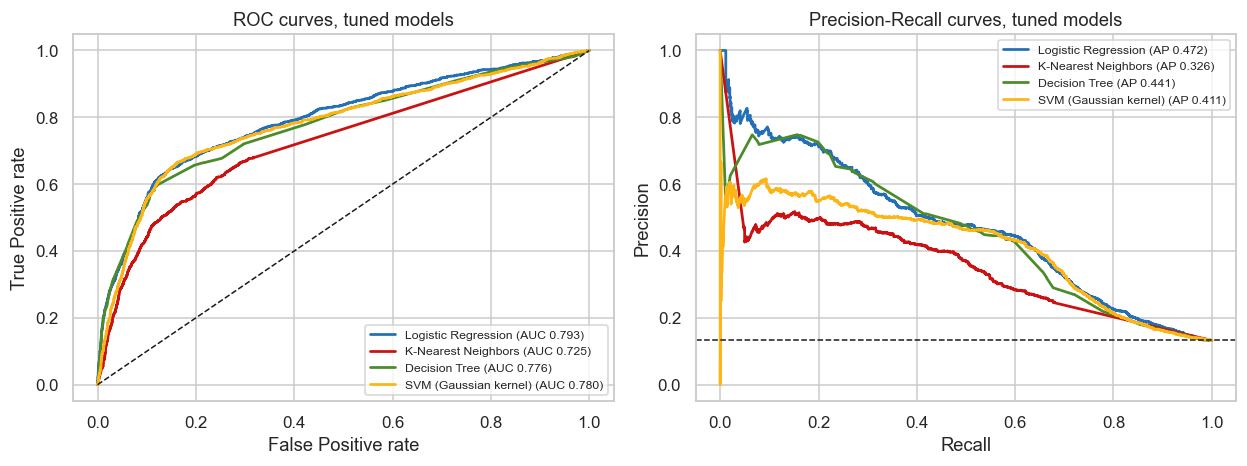

In [52]:
# ROC curves and precision-recall curves, displayed side by side
palette = {"Logistic Regression": "#2370B7",
           "K-Nearest Neighbors": "#CB1212", 
           "Decision Tree": "#4C8B2B",
           "SVM (Gaussian kernel)": "#FDB515"
           }

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

for name, score in tuned_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    axes[0].plot(fpr, tpr, color=palette[name], linewidth=1.8,
                 label=f"{name} (AUC {roc_auc_score(y_test, score):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, score)
    axes[1].plot(rec, prec, color=palette[name], linewidth=1.8,
                 label=f"{name} (AP {average_precision_score(y_test, score):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set_xlabel("False Positive rate")
axes[0].set_ylabel("True Positive rate")
axes[0].set_title("ROC curves, tuned models")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].axhline(y_test.mean(), color="k", linestyle="--", linewidth=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curves, tuned models")
axes[1].legend(fontsize=8, loc="upper right")

plt.tight_layout()

plt.savefig("images/tuned_roc_pr.png")
plt.show()

#### Obesrvations - Tuning and ROC + PR

**ROC Curve:**
Three of our tuned models (Logistic Regression, Decision Tree, SVM) almost overlap with each other on the ROC curve, but the K-Nearest Neighbors model sits below the others across the whole range, implying it is inferior than the other 3 models. 

**PR Curve:**
All models sit above the black dash lines (base rate of 15.5%), therefore all 4 models captures signals from the features.



#### Model Selection

We will take a closer look at a few tuned "best" models from our 4 Classifier types, to determine the final model

#### Decision Tree

In [53]:
# Decision Tree
# Display again the best hyperparameters for tuned Decision Tree model from GridSearch
print("="*120)
print("Best Hyperparameters for Decision Tree Model")
print("="*120)
param_text = searches["Decision Tree"].best_params_.items()
cleaned_text = {k.replace("model__", ""): v for k, v in param_text}
print(cleaned_text)
print("="*120)

Best Hyperparameters for Decision Tree Model
{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 5}


In [54]:
# Explore permutation importance of our Decision Tree model with best hyperparameters from previous GridSearch, 
# to check feature ranking

tree_perm = permutation_importance(searches["Decision Tree"].best_estimator_, X_test, y_test, scoring="f1", n_repeats=5, random_state=10)
tree_importance = pd.Series(tree_perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

print(tree_importance.head(8).round(4).to_string())

nr.employed       0.2611
euribor3m         0.0942
month             0.0235
contact           0.0130
age               0.0123
cons.price.idx    0.0103
poutcome          0.0025
job               0.0020


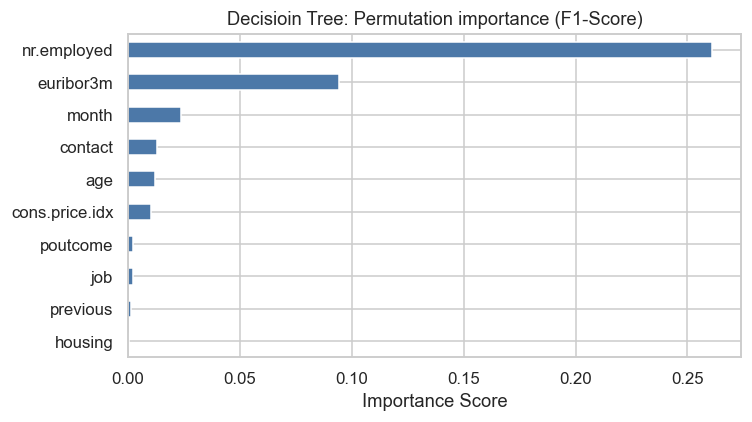

In [55]:
# Bar chart to visualize permutation importance of our Decision Tree model with best hyperparameters from previous GridSearch, 
# to check feature ranking

ax = tree_importance.head(10).sort_values().plot.barh(figsize=(7, 4), color="#4c78a8")
ax.set(title="Decisioin Tree: Permutation importance (F1-Score)", xlabel="Importance Score")
plt.tight_layout()

plt.savefig("images/tree_imp.png")
plt.show()

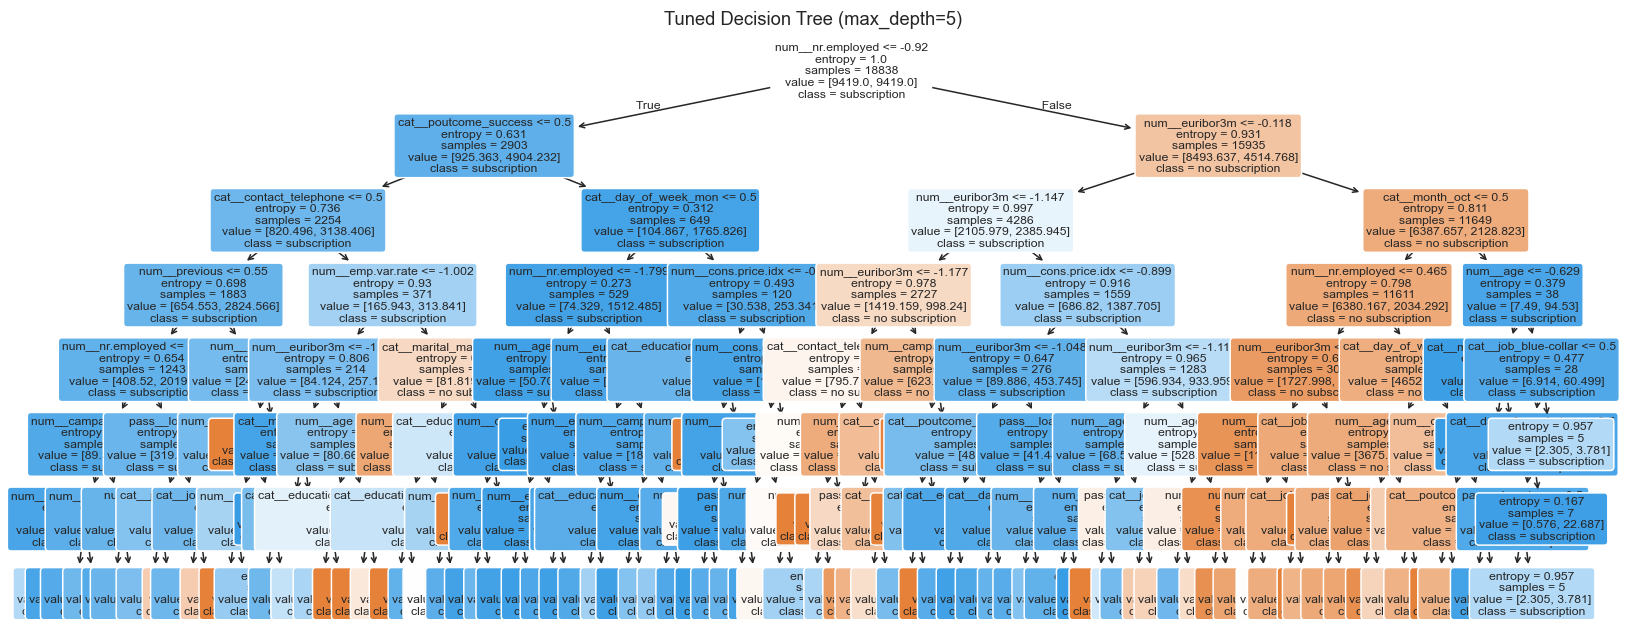

In [56]:
# Is the tuned tree shallow enough for business to read?
# Display the decision tree for visual inspection

best_tree = searches["Decision Tree"].best_estimator_
tree_feature_names = best_tree.named_steps["transformer"].get_feature_names_out()

fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(best_tree.named_steps["model"], feature_names=tree_feature_names,
          class_names=["no subscription", "subscription"], filled=True, rounded=True,
          fontsize=8, ax=ax)
ax.set_title("Tuned Decision Tree (max_depth=5)")
plt.tight_layout()

plt.savefig("images/best_tree.png")
plt.show()
###

Observation:

- The Decision Tree with tuned hyperparameter tree depth = 7 is impossible to read, therefore impractical to explain to the bank business marketing team

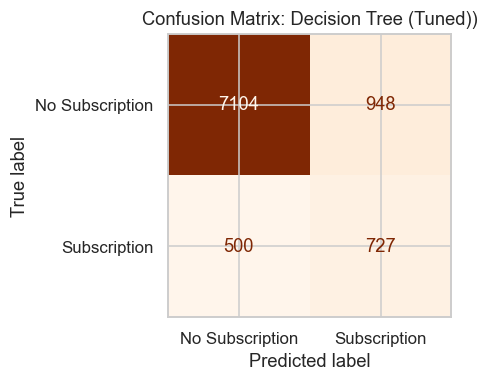

In [57]:
# Evaluate our "best" Decision Tree model using Confusion Matrix

best_tree.fit(X_train, y_train)
tree_pred = best_tree.predict(X_test)
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, tree_pred, display_labels=["No Subscription", "Subscription"],
    cmap="Oranges", colorbar=False, ax=ax
)
ax.set_title("Confusion Matrix: Decision Tree (Tuned))")
plt.tight_layout()

plt.savefig("images/c_matrix_tree.png")
plt.show()

Further Tuning: Decision Threshold

Every metric reported so far used the default cutoff of 0.5. With our base success subscription rate is only 11.27%, a default 
threshold of 0.5 is not right. We will choose the threshold that maximizes F1 score, using out-of-fold predictions on the **training** set, not the test set that we report on.

In [64]:
# Determine out-of-fold probabilities on the training set for our best Decision Tree model
# [:, 1] slices the results to isolate probability of positive class
oof_tree_proba = cross_val_predict(best_tree, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec_tr, rec_tr, thr_tr = precision_recall_curve(y_train, oof_tree_proba)
f1_tr = 2 * prec_tr * rec_tr / (prec_tr + rec_tr + 1e-12)

# find index for max value, ignoring NaNs
best_idx = int(np.nanargmax(f1_tr[:-1]))
f1_threshold = thr_tr[best_idx]

# Decision Tree
# Display the best threshold for tuned Decision Tree model from training data
print("="*120)
print("Decision Tree: Decision Thresholds Tuning")
print("="*120)
print("F1-optimal threshold from training folds:", round(f1_threshold, 3))
print("Cross-validated F1 at that threshold:    ", round(f1_tr[best_idx], 4))
print("="*120)

Decision Tree: Decision Thresholds Tuning
F1-optimal threshold from training folds: 0.646
Cross-validated F1 at that threshold:     0.512


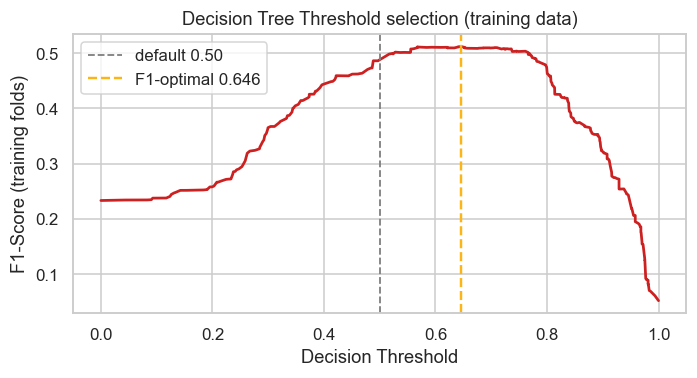

In [65]:
# Line Plot to visualize F1 as a function of the threshold, estimated on training folds as noteed above
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(thr_tr, f1_tr[:-1], color="#CD2121", linewidth=1.8)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1.2, label="default 0.50")
ax.axvline(f1_threshold, color="#FDB515", linestyle="--", linewidth=1.6,
           label=f"F1-optimal {f1_threshold:.3f}")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("F1-Score (training folds)")
ax.set_title("Decision Tree Threshold selection (training data)")
ax.legend()
plt.tight_layout()

plt.savefig("images/tree_threshold.png")
plt.show()

In [114]:
# Apply the training-selected Decision Threshold to the test set, one time
test_proba = best_tree.predict_proba(X_test)[:, 1]

threshold_rows = []
for label, t in [("Decisioin Tree: default 0.500", 0.5), (f"Decisioin Tree: F1-optimal {f1_threshold:.3f}", f1_threshold)]:
    pred_t = (test_proba >= t).astype(int)
    threshold_rows.append({
        "Model + Threshold": label,
        "Accuracy": accuracy_score(y_test, pred_t),
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t),
        "F1": f1_score(y_test, pred_t),
        "ROC AUC": roc_auc_score(y_test, test_proba)
    })

pd.DataFrame(threshold_rows).round(4)

,Model + Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Decisioin Tree: default 0.500,0.8439,0.4340,0.5925,0.501,0.7763
1,Decisioin Tree: F1-optimal 0.646,0.8470,0.4402,0.5786,0.500,0.7763


#### Decision Tree: Observations

- The Decision Tree with tuned hyperparameter tree depth = 7 is impossible to read, therefore impractical to explain to the bank business marketing team
- Its high F1-Score may have been achieved through over-fitting with tree depth = 7
- Confusion Matrix shows our Decision Tree model is still have more False Positives (948) compared to True Positives (727)
- Adjusting the **decision threshold** from 0.500 to 0.646 did *not* help improve F1-score and other performance metrics.
- Also, somehow the tuned Decision Tree model ranked `poutcome` feature very low as a predictor, which is counter-intuitive to our earlier visual findings

Therefore we shall explore our next best model: SVM (Gaussian kernel)


#### Next Best Model: SVM (Gaussian kernel)

In [66]:
# SVM (Gaussian kernel)
# Display again the best hyperparameters for tuned SVM model from GridSearch
print("="*120)
print("Best Hyperparameters for SVM Model")
print("="*120)
param_text = searches["SVM (Gaussian kernel)"].best_params_.items()
cleaned_text = {k.replace("model__", ""): v for k, v in param_text}
print(cleaned_text)
print("="*120)

Best Hyperparameters for SVM Model
{'C': 1, 'class_weight': 'balanced', 'gamma': 0.1}


In [68]:
# Explore permutation importance of our SVM model with best hyperparameters from previous GridSearch, 
# to check feature ranking

svm_perm = permutation_importance(searches["SVM (Gaussian kernel)"].best_estimator_, X_test, y_test, scoring="f1", n_repeats=5, random_state=10)
svm_importance = pd.Series(svm_perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

print("="*120)
print("Feature Importance ranking from tuned SVM Model")
print("="*120)
print(svm_importance.head(8).round(4).to_string())
print("="*120)

Feature Importance ranking from tuned SVM Model
emp.var.rate      0.1247
cons.conf.idx     0.0474
month             0.0444
cons.price.idx    0.0256
nr.employed       0.0126
age               0.0102
poutcome          0.0094
day_of_week       0.0083


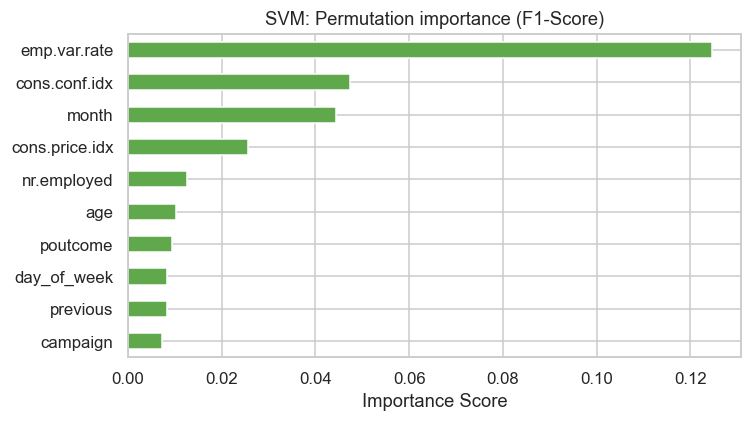

In [69]:
# Bar chart to visualize permutation importance of our SVM model with best hyperparameters from previous GridSearch, 

ax = svm_importance.head(10).sort_values().plot.barh(figsize=(7, 4), color="#60a84c")
ax.set(title="SVM: Permutation importance (F1-Score)", xlabel="Importance Score")
plt.tight_layout()

plt.savefig("images/svm_imp.png")
plt.show()

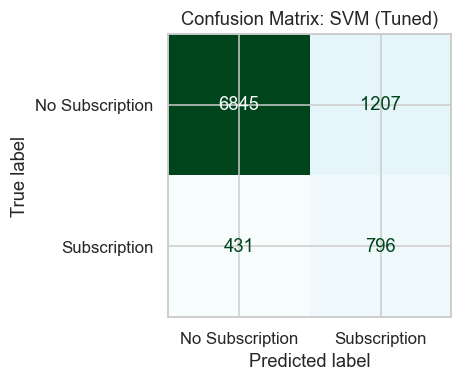

In [70]:
# Evaluate our "best" SVM model using Confusion Matrix

best_svm = searches["SVM (Gaussian kernel)"].best_estimator_

best_svm.fit(X_train, y_train)
svm_pred = best_svm.predict(X_test)
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred, display_labels=["No Subscription", "Subscription"],
    cmap="BuGn", colorbar=False, ax=ax
)
ax.set_title("Confusion Matrix: SVM (Tuned)")
plt.tight_layout()

plt.savefig("images/c_matrix_svm.png")
plt.show()

In [71]:
# Visualize our best SVM model
best_svm

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['age','job','marital',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, al

#### Confusion Matrix for Model Evalutaion

Examine metrics using a Confusion Matrix that is more useful for imbalanced classes in this case.

<center>
    <img src = images/c_matrix_logreg.png width = 30%/>
    <img src = images/c_matrix_tree.png width = 30%/>
    <img src = images/c_matrix_svm.png width = 30%/>
</center>

#### Manual Approach to Evaluation Metrics (Simple + Select Models)

Examine metrics using manual calculations for Precision, Recall and F1

In [72]:
# Manually populate metrics for positive class, instead of majority class
# TP = True Positives
# FP = False Positives
# FN = False Negatives

metric_data = []
metric_data = [["Logistic Regression (default)", 305, 155, 922], ["Decisioin Tree: (F1-optimal)", 727, 948, 500], ["SVM (Tuned)", 796, 1207, 431]]
metric_df = pd.DataFrame(metric_data, columns=["Model", "TP", "FP", "FN"])

# Vectorized calculations for Precision for positive class, Recall and F1, instead of majority class
# Precision Score to avoid FP (Type I errors) = TPs / (FPs + TPs)
# Recall Score to avoid FN (Type II errors)   = TPs / (TPs + FNs)
# F1 (Positive Class) = 2 × (recall × precision) ÷ (recall + precision)

metric_df["Precision"] = metric_df["TP"] / (metric_df["FP"] + metric_df["TP"])
metric_df["Recall"] = metric_df["TP"] / (metric_df["TP"] + metric_df["FN"])
metric_df["F1"] = (2 * metric_df["Precision"] * metric_df["Recall"]) / (metric_df["Precision"] + metric_df["Recall"])

print(round(metric_df, 4))


                           Model   TP    FP   FN  Precision  Recall      F1
0  Logistic Regression (default)  305   155  922     0.6630  0.2486  0.3616
1   Decisioin Tree: (F1-optimal)  727   948  500     0.4340  0.5925  0.5010
2                    SVM (Tuned)  796  1207  431     0.3974  0.6487  0.4929


Observations

- Original simple Logistic Regression model has high Precision but low Recall, and a very low F1-score for positive class
- Our F1-optimal Decison Tree model has okay mix of Precision and Recall, giving a good F1 score
- Our tuned SVM model has bad Precision but good Recall, therefore combined into a good F1 score

#### Auto-gen Approach to Evaluation Metrics (3 tuned models)

Examine metrics using auto generated Precision, Recall and F1 from previous sections

In [73]:
# Set index for original GridSearch model result metrics for easy merge with Decison Tree threshold-tuned metrics
tuned_results_df.set_index("Model", inplace=True)

In [115]:
# Merge SVM metrics with Decison Tree threshold-tuned metrics

threshold_rows.append({
        "Model + Threshold": "SVM (Gaussian kernel)",
        "Accuracy": tuned_results_df.loc["SVM (Gaussian kernel)", "Test Accuracy"],
        "Precision": tuned_results_df.loc["SVM (Gaussian kernel)", "Test Precision"],
        "Recall": tuned_results_df.loc["SVM (Gaussian kernel)", "Test Recall"],
        "F1": tuned_results_df.loc["SVM (Gaussian kernel)", "Test F1"],
        "ROC AUC": tuned_results_df.loc["SVM (Gaussian kernel)", "Test ROC AUC"]
    })

# Performance Metrics for our final model candidates
print("="*100)
print("Evaluation Metrics for final Model candidates")
print("="*100)
print(pd.DataFrame(threshold_rows).round(4))
print("="*100)


Evaluation Metrics for final Model candidates
                  Model + Threshold  Accuracy  Precision  Recall      F1  ROC AUC
0     Decisioin Tree: default 0.500    0.8439     0.4340  0.5925  0.5010   0.7763
1  Decisioin Tree: F1-optimal 0.646    0.8470     0.4402  0.5786  0.5000   0.7763
2             SVM (Gaussian kernel)    0.8235     0.3974  0.6487  0.4929   0.7799


Observations

- All 3 models have good F1 scores
- The 2 Decision Tree models (default threshold and F1-tuned threshold) have very similar performance metrics
- Our tuned SVM model has bad Precision but good Recall, therefore combined into a good F1 score

#### Final Model Selection

We select the **SVM with Gaussian kernel** as the final model for deployment, even though all 3 final model candidates resulted in close to the same F1 score.

Reasons

- The 7-level tuned Decision Tree is difficult and complex to interpret and action on, while SVM's top predictors can be explained to the bank marketing team, 
- SVM produces a good F1 score given the class imbalance in our case

Potential Tradeoffs

- SVM models usually run slower than Linear Regression, KNN and Decision Tree. e.g., grid search for SVM took 4+ minutes
- SVM does not give coefficients to business to explain the weights of the top predictor features
- SVM models use distance as decision, so there is no decision threshold for further optimization. We could use parameter `probability=True` but this will make the SVM model run even slower.

#### Scoring Final Model

In [ ]:
# Again, display Performance Metrics for our final model:
print("="*120)
print("Performance Metrics for Final Model: SVM")
print("="*120)
# print(tuned_results_df.loc[tuned_results_df["Model"] == "SVM (Gaussian kernel)"])
print(tuned_results_df.loc["SVM (Gaussian kernel)"])
print("="*120)

Performance Metrics for Final Model: SVM
Search Time(s)    278.1000
CV F1               0.4924
Test Accuracy       0.8235
Test Precision      0.3974
Test Recall         0.6487
Test F1             0.4929
Test ROC AUC        0.7799
Name: SVM (Gaussian kernel), dtype: float64


---

## Findings

### Findings on Comparing Classifiers

**Classifier Model Evaluation at First Glance**

- For our 4 basic models, SVM with a Gaussian kernel performs best in terms of Test Accuracy (0.8855). 

**Target Class is highly imbalanced**

- The confusion matrix and other data exploration metrics confirm that our target classes (Yes/No on term-deposit subscriptions) are highly imbalanced

**Accuracy Score is not a good classifier evaluation metric for this scenario**

- This is due to the imbalance in target class. Also, Test Accuracy varies very less across the 4 basic models, so does not help in choosing a model. KNN has the second lowest Test Accuracy score of the four models, but the highest F1-Score for positive class.  This again demonstrates that ranking these models based on Accuracy alone is not sufficient.  
- Even worse, our hyperparameter tuning exercise did not improve Accuracy Scores much; in fact it degraded 3 out of the 4 default models!

**F1-Score is used as our model evaluation metric**

- Instead of using Accuracy Score, we use F1-Score for the positive class, as a weighted average of both Precision and Recall

**Tuning improved F1-Scores for 3 Classifier types only, reaching a plateau**

- Our hyperparameter tuning exercise improved F1-Scores for 3 out of the 4 model types: Logistic Regression, Decision Tree and SVM, but reached a plateau (0.47 to 0.50). This implies all three tuned models extract about the same amount of signal from the Bank information data, and the signal ceiling is set by the features rather than by the machine learning algorithm. 
- Tuning improves F1 more than it improves Accuracy Scores

**SVM with Gaussian kernel is our model of choice**

- SVM produces a good F1 score given the class imbalance in our case
- Our tuned SVM model has bad Precision but good Recall, therefore combined into a good F1 score
- Tradeoff is that SVM models usually run slower than the other models

**Tuned Decision Tree is best on paper but not good in practice**

- Our tuned Decision Tree model resulted in the best Test Set F1-Score, but with the tuned hyperparameter tree depth = 7 is impossible to read, therefore impractical to explain to the bank business marketing team

**K-Nearest Neighbors (KNN) is the worst choice for this scenario**

- Our default and tuned KNN models report the same lowest F1-Score.  In addition, 3 of our 4 tuned models (Logistic Regression, Decision Tree, SVM) almost overlap with each other on the ROC curve, but our KNN model sits below the others across the whole range, implying it is inferior to the other 3 models. 



### Findings and Recommendations for Business

**Closely follow the macro-economic indicators**

- Quarterly employment variation rate: A positive rate signals job growth and economic expansion, and can boost term-deposit subscription rate
- monthly consumer confidence index: Higher consumer confidence can boost term-deposit subscription rate

**Follow seasonal trends**
- Month: The months of Mar, Sep, Oct and Dec show high successful subscription rates. Banks should consider investing resources to make more campaign contacts during these months. This effect seems to be seasonal rather than structural.

**Use previous campaign history as a guide**

- Previous campaign outcome is still a good predictor because previous campaign successes are closely related to current campaign successes.

**Last call duration can be deceiving**

- Last call duration and the number of previous calls may show strong relationship with target outcome, but they impact negative subscriptions more than positive subscriptions, therefore both are not good predictors of successful subscriptions.

**Client demographics may not be the main driver**

- Somehow our model shows other client demographics variables are not that useful in deciding successful subscriptions. E.g., education, housing, load, marital status, etc.  Business is advised to use mainly “previous campaign outcome” as the main individual client’s predictor.





---

## Next Steps

1. Business Priority: Deploy the tuned SVM model to production. Bank Marketing Team should determine what to prioritize in marketing campaign: 

- Reduce False Positives to reduce contact calls and save cost (measured by Precision Score), or 
- Reduce False Negatives to improve subscription rates (measured by Recall Score)

     Then use the mode’s Confusion Matrix to guide effectiveness

2. Monthly Data: Data for months of Jan and Feb are missing. Marketing team should gather those data to refit the model pipeline, in order to form a more complete picture and to evaluate/improve model for predictions. Current model is fitted based on data when a campaign call happened, therefore data was not recorded when no calls were made.

3. Yearly Trend: Successful Subscription percentage rose over the years, although the total number of calls fell. Therefore the business team has done something right to improve subscription rates year-over-year.  This trend deserves further investigations, as a trend analysis (in addition to classifier model evaluation). And we should continue yearly data analysis, on top of monthly data.

4. Additional Classifier Models: in addition to the 4 classifier model types compared in the exercise, we should also explore using Ensemble techniques (Module 20), e.g., Random Forests and Boosting. Also, we used default kernel (rbf or Gaussian) for SVM tuning in this exercise; we should also explore other kernels (linear, ploy, sigmoid) in future. This may improve our predictions, because our 3 current tuned models are similar in terms of F1 Scores.

